In [1]:
# Import the required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')

In [2]:
# Read the files into DataFrame - users
users = pd.read_csv('data\\dirty_users.csv', index_col=0)
users.head(2)

,id,age,gender,occupation,zip code
0,821,37.0,M,engineer,77845
1,212,49.0,NaN,educator,61401


In [3]:
# Read the files into DataFrame - users
movies = pd.read_csv('data\\dirty_movies.csv', index_col=0)
movies.head(2)

,movie id,movie title,release date,video release date,IMDb URL,genres
0,1475,Bhaji on the Beach (1993),01-Jan-1993,NaN,http://us.imdb.com/M/title-exact?Bhaji%20on%20...,"Comedy,Drama"
1,1463,"Boys, Les (1997)",01-Jan-1997,NaN,http://us.imdb.com/M/title-exact?imdb-title-11...,Comedy


In [4]:
# Read the files into DataFrame - users
data = pd.read_csv('data\\dirty_data.csv', index_col=0)
data.head(2)

,user_id,movies_id,rating,timestamp
0,196,242,3.0,881250949
1,186,302,3.0,891717742


In [5]:
# Check summary information for DataFrames - users
users.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1037 entries, 0 to 1036
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   id          1037 non-null   int64  
 1   age         926 non-null    float64
 2   gender      936 non-null    object 
 3   occupation  938 non-null    object 
 4   zip code    1037 non-null   object 
dtypes: float64(1), int64(1), object(3)
memory usage: 48.6+ KB


In [6]:
# Check summary information for DataFrames - movies
movies.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1766 entries, 0 to 1765
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   movie id            1766 non-null   int64  
 1   movie title         1766 non-null   object 
 2   release date        1765 non-null   object 
 3   video release date  0 non-null      float64
 4   IMDb URL            1763 non-null   object 
 5   genres              1581 non-null   object 
dtypes: float64(1), int64(1), object(4)
memory usage: 96.6+ KB


In [7]:
# Check summary information for DataFrames - data
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 100000 entries, 0 to 99999
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   user_id    100000 non-null  int64  
 1   movies_id  100000 non-null  int64  
 2   rating     97981 non-null   float64
 3   timestamp  100000 non-null  int64  
dtypes: float64(1), int64(3)
memory usage: 3.8 MB


> <p style="background-color: orange"> In other to carry out a full EDA on the dataset, the first step would be to merge all the data into a single DataFrame





</p>

In [8]:
# Merge data and users
temp_df = pd.merge(data, users, left_on='user_id', right_on='id', how='left')

In [9]:
temp_df.head()

,user_id,movies_id,rating,timestamp,id,age,gender,occupation,zip code
0,196,242,3.0,881250949,196,NaN,M,writer,55105
1,186,302,3.0,891717742,186,39.0,F,executive,00000
2,22,377,1.0,878887116,22,NaN,M,writer,40206
3,244,51,2.0,880606923,244,NaN,M,NaN,80525
4,166,346,1.0,886397596,166,47.0,M,educator,55113


In [10]:
# Merge temporary result with movies
movies_ratings = temp_df.merge(movies, left_on='movies_id', right_on='movie id ')

In [11]:
movies_ratings

,user_id,movies_id,rating,timestamp,id,age,gender,occupation,zip code,movie id,movie title,release date,video release date,IMDb URL,genres
0,196,242,3.0,881250949,196,NaN,M,writer,55105,242,Kolya (1996),24-Jan-1997,NaN,http://us.imdb.com/M/title-exact?Kolya%20(1996),Comedy
1,186,302,3.0,891717742,186,39.0,F,executive,00000,302,L.A. Confidential (1997),01-Jan-1997,NaN,http://us.imdb.com/M/title-exact?L%2EA%2E+Conf...,"Crime,Film-Noir,Mystery,Thriller"
2,22,377,1.0,878887116,22,NaN,M,writer,40206,377,Heavyweights (1994),01-Jan-1994,NaN,http://us.imdb.com/M/title-exact?Heavyweights%...,"Children's,Comedy"
3,244,51,2.0,880606923,244,NaN,M,NaN,80525,51,Legends of the Fall (1994),01-Jan-1994,NaN,http://us.imdb.com/M/title-exact?Legends%20of%...,"Drama,Romance,War,Western"
4,166,346,1.0,886397596,166,47.0,M,educator,55113,346,Jackie Brown (1997),01-Jan-1997,NaN,http://us.imdb.com/M/title-exact?imdb-title-11...,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
115209,880,476,3.0,880175444,880,13.0,M,NaN,83702,476,"First Wives Club, The (1996)",14-Sep-1996,NaN,http://us.imdb.com/M/title-exact?First%20Wives...,Comedy
115210,716,204,5.0,879795543,716,36.0,F,NaN,44265,204,Back to the Future (1985),01-Jan-1985,NaN,http://us.imdb.com/M/title-exact?Back%20to%20t...,NaN
115211,276,1090,1.0,874795795,276,21.0,M,student,95064,1090,Sliver (1993),01-Jan-1993,NaN,http://us.imdb.com/M/title-exact?Sliver%20(1993),Thriller
115212,13,225,2.0,882399156,13,47.0,M,NaN,29206,225,101 Dalmatians (1996),27-Nov-1996,NaN,http://us.imdb.com/M/title-exact?101%20Dalmati...,"Children's,Comedy"


**Pre-clean EDA**

In [12]:
movies_ratings.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 115214 entries, 0 to 115213
Data columns (total 15 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   user_id             115214 non-null  int64  
 1   movies_id           115214 non-null  int64  
 2   rating              112883 non-null  float64
 3   timestamp           115214 non-null  int64  
 4   id                  115214 non-null  int64  
 5   age                 101725 non-null  float64
 6   gender              104246 non-null  object 
 7   occupation          101814 non-null  object 
 8   zip code            115214 non-null  object 
 9   movie id            115214 non-null  int64  
 10  movie title         115214 non-null  object 
 11  release date        115205 non-null  object 
 12  video release date  0 non-null       float64
 13  IMDb URL            115200 non-null  object 
 14  genres              102777 non-null  object 
dtypes: float64(3), int64(5), object(7)

There are isues identified from here


- There is missing data
- Age column is an `float` data type - should be an `Integer` data type
- release date is an `object` data type - should be a `Datetime` data type
- `user_id` and `id` represent the same variable - one should be dropped
- `movie_id` and `movie id ` represent the same variable - one should be dropped
- ` video release date` are all null - column to be dropped
- `Genre` columns has multiple categories - change to one-hot encoding?


In [13]:
# Check the descriptive statistics - numeric
movies_ratings.describe()

,user_id,movies_id,rating,timestamp,id,age,movie id,video release date
count,115214.000000,115214.000000,112883.000000,1.152140e+05,115214.000000,101725.000000,115214.000000,0.0
mean,464.366041,429.011162,3.509997,8.834628e+08,464.366041,32.791241,429.011162,NaN
std,267.236372,333.751162,1.914458,5.327716e+06,267.236372,19.435918,333.751162,NaN
min,1.000000,1.000000,-19.000000,8.747247e+08,1.000000,-10.000000,1.000000,NaN
25%,257.000000,176.000000,3.000000,8.794459e+08,257.000000,24.000000,176.000000,NaN
50%,448.000000,322.000000,4.000000,8.829104e+08,448.000000,30.000000,322.000000,NaN
75%,687.000000,641.750000,4.000000,8.881046e+08,687.000000,40.000000,641.750000,NaN
max,943.000000,1682.000000,25.000000,8.932866e+08,943.000000,150.000000,1682.000000,NaN


- Negative and invalid values in ratings
- Outliers in the `Age` column

In [14]:
# Check the descriptive statistics - 
movies_ratings.describe(include='O')

,gender,occupation,zip code,movie title,release date,IMDb URL,genres
count,104246,101814,115214,115214,115205,115200,102777
unique,2,23,795,1664,240,1660,350
top,M,student,10019,Star Wars (1977),01-Jan-1995,http://us.imdb.com/M/title-exact?Star%20Wars%2...,Drama
freq,77315,21947,1668,646,11716,646,12578


- The highest frequency are  `male`and `students` and `return of the jedi`

In [15]:
# Check the DataFrame again
movies_ratings.head()

,user_id,movies_id,rating,timestamp,id,age,gender,occupation,zip code,movie id,movie title,release date,video release date,IMDb URL,genres
0,196,242,3.0,881250949,196,NaN,M,writer,55105,242,Kolya (1996),24-Jan-1997,NaN,http://us.imdb.com/M/title-exact?Kolya%20(1996),Comedy
1,186,302,3.0,891717742,186,39.0,F,executive,00000,302,L.A. Confidential (1997),01-Jan-1997,NaN,http://us.imdb.com/M/title-exact?L%2EA%2E+Conf...,"Crime,Film-Noir,Mystery,Thriller"
2,22,377,1.0,878887116,22,NaN,M,writer,40206,377,Heavyweights (1994),01-Jan-1994,NaN,http://us.imdb.com/M/title-exact?Heavyweights%...,"Children's,Comedy"
3,244,51,2.0,880606923,244,NaN,M,NaN,80525,51,Legends of the Fall (1994),01-Jan-1994,NaN,http://us.imdb.com/M/title-exact?Legends%20of%...,"Drama,Romance,War,Western"
4,166,346,1.0,886397596,166,47.0,M,educator,55113,346,Jackie Brown (1997),01-Jan-1997,NaN,http://us.imdb.com/M/title-exact?imdb-title-11...,NaN


In [16]:
# Check for missing data
movies_ratings.isna().sum()

user_id                    0
movies_id                  0
rating                  2331
timestamp                  0
id                         0
age                    13489
gender                 10968
occupation             13400
zip code                   0
movie id                   0
movie title                0
release date               9
video release date    115214
IMDb URL                  14
genres                 12437
dtype: int64

In [17]:
# Lets check as a percentage of total dataset rows 
round(movies_ratings.isna().sum() / len(movies_ratings) *100, 2)

user_id                 0.00
movies_id               0.00
rating                  2.02
timestamp               0.00
id                      0.00
age                    11.71
gender                  9.52
occupation             11.63
zip code                0.00
movie id                0.00
movie title             0.00
release date            0.01
video release date    100.00
IMDb URL                0.01
genres                 10.79
dtype: float64

In [18]:
# Sort from highest to lowest missing data
(round(movies_ratings.isna().sum() / len(movies_ratings) *100)).sort_values(ascending=False)

video release date    100.0
age                    12.0
occupation             12.0
genres                 11.0
gender                 10.0
rating                  2.0
user_id                 0.0
movies_id               0.0
timestamp               0.0
id                      0.0
zip code                0.0
movie id                0.0
movie title             0.0
release date            0.0
IMDb URL                0.0
dtype: float64

<Axes: >

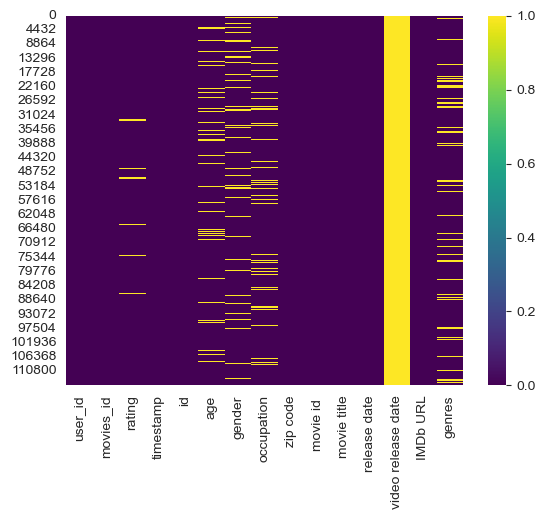

In [19]:
# Visualise missing data with heatmap
sns.heatmap(movies_ratings.isna(), cmap='viridis')

*Imputation Strategies*

- `Video release date` - drop
- `genres` - fill with specific - 'None' or `Not classifed' or 'unknown'
- `Age` - fill with median
- `Occupation` - fill with mode or ffill or bfill
- `gender` - fill with mode or ffill or bfill
- `rating` - drop or mean or median
- `release date` - drop or ffill or bfill 

In [20]:
# Confirm unique categories on the categorical variables
movies_ratings['user_id'].value_counts()

user_id
405    1552
846    1266
279     914
655     720
727     678
       ... 
93       20
809      20
309      20
740      20
364      20
Name: count, Length: 943, dtype: int64

- There are 943 unique users - with `user_i`d 405 giving the highest count of ratings

In [21]:
movies_ratings['movies_id'].value_counts()

movies_id
50      646
202     630
181     562
258     558
100     557
       ... 
1340      1
1525      1
1593      1
1348      1
1641      1
Name: count, Length: 1682, dtype: int64

- There are 1682 unique movies - with `movies_id` - 50 giving the highest count of ratings

In [22]:
movies_ratings['gender'].value_counts()

gender
M    77315
F    26931
Name: count, dtype: int64

In [23]:
# Check as percentages -in integer
(movies_ratings['gender'].value_counts() / len(movies_ratings) * 100).astype(int)

gender
M    67
F    23
Name: count, dtype: int32

- There are 67% males giving ratings - will there be gender bias in overall ratings?

In [24]:
# Check percentage in occupations
(movies_ratings['occupation'].value_counts() / len(movies_ratings) * 100).astype(int)

occupation
student          19
other             9
educator          8
engineer          7
programmer        6
administrator     6
librarian         5
writer            5
healthcare        3
executive         3
technician        2
artist            2
entertainment     1
scientist         1
retired           1
marketing         1
lawyer            0
salesman          0
none              0
doctor            0
homemaker         0
marketing^R`      0
studentT          0
Name: count, dtype: int32

- Data really skewed towards students - 19% of all ratings - how does that reflect in age distribution?
- There is bad data - `marketing^R'` and `studentT` - needs to be cleaned

In [25]:
movies_ratings['genres'].value_counts()

genres
Drama              12578
Comedy              8831
Comedy,Romance      5788
Drama,Romance       4902
Action,Thriller     3503
                   ...  
unknown                1
Docuxentary            1
7f!Q=<9T2l5)A&/        1
DFama                  1
H{ah@                  1
Name: count, Length: 350, dtype: int64

- There is bad data - `Docuxentary`, `7f!Q=<9T2l5)A&/` , `DFama` etc- needs to be cleaned

In [26]:
# Check for duplicated data
movies_ratings.duplicated().value_counts()

False    100000
True      15214
Name: count, dtype: int64

In [27]:
# View the duplicated ratings
movies_ratings[movies_ratings.duplicated(keep=False)]

,user_id,movies_id,rating,timestamp,id,age,gender,occupation,zip code,movie id,movie title,release date,video release date,IMDb URL,genres
14,224,29,3.0,888104457,224,-10.0,F,educator,43512,29,Batman Forever (1995),01-Jan-1995,NaN,http://us.imdb.com/M/title-exact?Batman%20Fore...,"Action,Adventure,Comedy,Crime"
15,224,29,3.0,888104457,224,-10.0,F,educator,43512,29,Batman Forever (1995),01-Jan-1995,NaN,http://us.imdb.com/M/title-exact?Batman%20Fore...,"Action,Adventure,Comedy,Crime"
16,224,29,3.0,888104457,224,-10.0,F,educator,43512,29,Batman Forever (1995),01-Jan-1995,NaN,http://us.imdb.com/M/title-exact?Batman%20Fore...,"Action,Adventure,Comedy,Crime"
17,224,29,3.0,888104457,224,-10.0,F,educator,43512,29,Batman Forever (1995),01-Jan-1995,NaN,http://us.imdb.com/M/title-exact?Batman%20Fore...,"Action,Adventure,Comedy,Crime"
25,299,144,4.0,877881320,299,29.0,NaN,doctor,63108,144,Die Hard (1988),01-Jan-1988,NaN,http://us.imdb.com/M/title-exact?Die%20Hard%20...,"Action,Thriller"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
115179,897,369,4.0,879993713,897,30.0,M,other,33484,369,Black Sheep (1996),02-Feb-1996,NaN,http://us.imdb.com/M/title-exact?Black%20Sheep...,NaN
115189,487,291,3.0,883445079,487,22.0,M,engineer,92121,291,Absolute Power (1997),14-Feb-1997,NaN,http://us.imdb.com/M/title-exact?Absolute%20Po...,"Mystery,Thrillerr@cW"
115190,487,291,3.0,883445079,487,22.0,M,engineer,92121,291,Absolute Power (1997),14-Feb-1997,NaN,http://us.imdb.com/M/title-exact?Absolute%20Po...,"Mystery,Thrillerr@cW"
115195,279,64,1.0,875308510,279,33.0,M,programmer,85251,64,"Shawshank Redemption, The (1994)",01-Jan-1994,NaN,http://us.imdb.com/M/title-exact?Shawshank%20R...,Drama


- There are `15214` duplicated records - this will be dropped

*Graphical EDA*

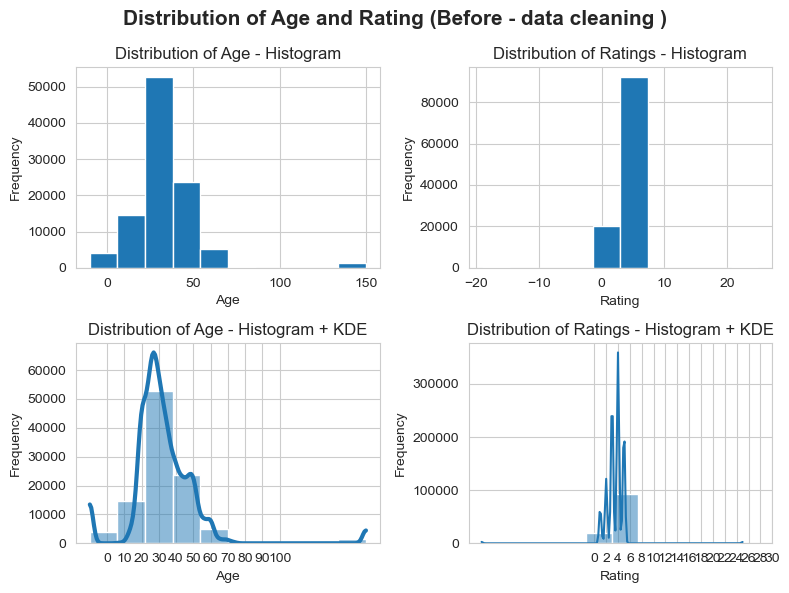

In [28]:
# Distribution of ratings - histogram & KDE
fig, axes = plt.subplots(2, 2, figsize=(8, 6),)

axes[0, 0].hist(movies_ratings['age'])
axes[0, 1].hist(movies_ratings['rating'])
sns.histplot(movies_ratings['age'], kde=True, ax=axes[1, 0], bins=10, line_kws={'linewidth':3})
sns.histplot(movies_ratings['rating'], kde=True, ax=axes[1, 1], bins=10)

# Customise plot
# Titles
fig.suptitle('Distribution of Age and Rating (Before - data cleaning )', fontsize=15, fontweight='bold')
axes[0, 0].set_title('Distribution of Age - Histogram')
axes[0, 1].set_title('Distribution of Ratings - Histogram')
axes[1, 0].set_title('Distribution of Age - Histogram + KDE')
axes[1, 1].set_title('Distribution of Ratings - Histogram + KDE')

# Axis labels
axes[0, 0].set_xlabel('Age')
axes[0, 0].set_ylabel('Frequency')
axes[0, 1].set_xlabel('Rating')
axes[0, 1].set_ylabel('Frequency')
axes[1, 0].set_xlabel('Age')
axes[1, 0].set_ylabel('Frequency')
axes[1, 1].set_xlabel('Rating')
axes[1, 1].set_ylabel('Frequency')

# Add more ticks to zoom in
axes[1, 0].set_xticks(np.arange(0, 101, 10))
axes[1, 1].set_xticks(np.arange(0, 31, 2))

fig.tight_layout()


plt.show();


> This confirms the existence of outliers in the `age` and `rating` columns - both positive and negative

> There is need to check the dataset documentation to confirm the rating range 

> Most frequent age is between 20 and 30 years old - which matches the studentship age

> Most frequent rating is between 3 and 4

> Both seem to follow a uniform distribution - effect of outlier inclusive at this point!

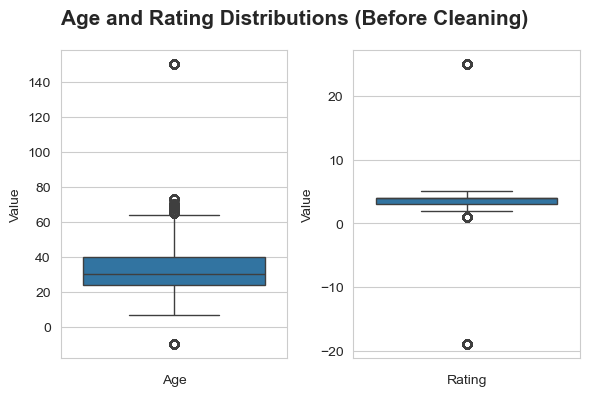

In [29]:
# Distribution of ratings - box plot
fig = plt.figure(figsize=(6, 4))
ax = fig.add_subplot(1, 2, 1)
sns.boxplot(data=movies_ratings, y='age', ax=ax)
ax.set_xlabel('Age')
ax.set_ylabel('Value')
ax = fig.add_subplot(1, 2, 2)
sns.boxplot(data=movies_ratings, y='rating', ax=ax)
ax.set_xlabel('Rating')
ax.set_ylabel('Value')

fig.suptitle('Age and Rating Distributions (Before Cleaning)', fontsize=15, fontweight='bold')
fig.tight_layout()
plt.show()

> Confirms the presence of outliers - which are bad data!

> The median age is 30 years - not affected by the outliers 

> 75% percentile is 40 years - that is 75% of the ages is 40 years and below

> It will be best to remove the outliers in rating to see the true values easily even though we know from `describe()` that median is 4

In [30]:
# let check unique list of movies without duplicates 
movies_ratings.drop_duplicates('movies_id') # not inplace

,user_id,movies_id,rating,timestamp,id,age,gender,occupation,zip code,movie id,movie title,release date,video release date,IMDb URL,genres
0,196,242,3.0,881250949,196,NaN,M,writer,55105,242,Kolya (1996),24-Jan-1997,NaN,http://us.imdb.com/M/title-exact?Kolya%20(1996),Comedy
1,186,302,3.0,891717742,186,39.0,F,executive,00000,302,L.A. Confidential (1997),01-Jan-1997,NaN,http://us.imdb.com/M/title-exact?L%2EA%2E+Conf...,"Crime,Film-Noir,Mystery,Thriller"
2,22,377,1.0,878887116,22,NaN,M,writer,40206,377,Heavyweights (1994),01-Jan-1994,NaN,http://us.imdb.com/M/title-exact?Heavyweights%...,"Children's,Comedy"
3,244,51,2.0,880606923,244,NaN,M,NaN,80525,51,Legends of the Fall (1994),01-Jan-1994,NaN,http://us.imdb.com/M/title-exact?Legends%20of%...,"Drama,Romance,War,Western"
4,166,346,1.0,886397596,166,47.0,M,educator,55113,346,Jackie Brown (1997),01-Jan-1997,NaN,http://us.imdb.com/M/title-exact?imdb-title-11...,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
111102,840,1674,4.0,891211682,840,39.0,M,artist,55406,1674,Mamma Roma (1962),01-Jan-1962,NaN,http://us.imdb.com/M/title-exact?Mamma%20Roma%...,Drama
112481,655,1640,3.0,888474646,655,NaN,F,healthcare,60657,1640,"Eighth Day, The (1996)",01-Nov-1996,NaN,"http://us.imdb.com/Title?Huiti%E8me+jour,+Le+(...",Drama
113379,655,1637,3.0,888984255,655,NaN,F,healthcare,60657,1637,Girls Town (1996),23-Aug-1996,NaN,http://us.imdb.com/M/title-exact?Girls%20Town%...,Drama
113621,655,1630,3.0,887428735,655,NaN,F,healthcare,60657,1630,"Silence of the Palace, The (Saimt el Qusur) (1...",02-Feb-1996,NaN,http://us.imdb.com/M/title-exact?Saimt%20el%20...,Drama


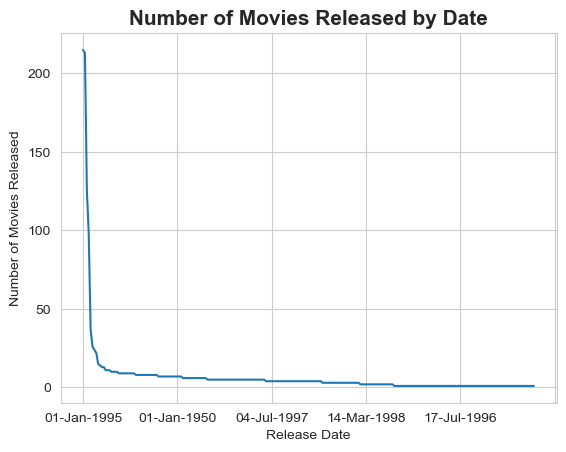

In [31]:
# Plot to reveal date with most releases
movies_ratings.drop_duplicates('movies_id')['release date'].value_counts().plot()
plt.ylabel('Number of Movies Released')
plt.xlabel('Release Date')
plt.title('Number of Movies Released by Date', fontsize=15, fontweight='bold');

In [32]:
(movies_ratings.drop_duplicates('movies_id')['release date'].value_counts()).sort_index(ascending=False)

release date
4-Feb-1971     1
31-May-1996    3
31-Jul-1996    1
31-Jan-1997    4
31-Dec-1997    1
              ..
01-Jan-1930    1
01-Jan-1926    1
01-Jan-1922    1
01-Feb-1998    2
01-Aug-1997    4
Name: count, Length: 240, dtype: int64

> There is need to use the right data type for the release date to get the correct trend plot
> 
> No recognised as date so not sorted chronologically 

**Data Cleaning**

From the pre-clean EDA above the following steps are proposed

- Missing data
    - `Video` release date` - drop
    - `genres` - fill with specific - `unknown'
    - `Age` - fill with median
    - `Occupation` - fill with ffill - from heatmap missing data is spaced
    - `gender` - fill with ffill - from heatmap missing data is well spaced
    - `rating` - drop - very small rows
    - `release date` - drop - very small rows
    - Remove the `IMDb URL` column - not needed for analysis

- Data Types
    - `age` - change to integer data type
    - `release date` - transform to a Datetime data type

- Data duplication
    - `user_id` and `id` represent the same variable - drop `id` column
    - `movie_id` and `movie id`  represent the same variable - drop `movie id`
    - Remove duplicate rows

- Data Transformation

    - Remove the `timestamp` column - not needed for analysis
    - Remove the bad data in categorical columns with string manipulation
    - Genre columns has multiple categories - change to one-hot encoding

    
- Outliers
    - Remove outliers in `rating` and `age` by clipping the values



In [33]:
# Veiw DataFrame 
movies_ratings.head(2)

,user_id,movies_id,rating,timestamp,id,age,gender,occupation,zip code,movie id,movie title,release date,video release date,IMDb URL,genres
0,196,242,3.0,881250949,196,NaN,M,writer,55105,242,Kolya (1996),24-Jan-1997,NaN,http://us.imdb.com/M/title-exact?Kolya%20(1996),Comedy
1,186,302,3.0,891717742,186,39.0,F,executive,00000,302,L.A. Confidential (1997),01-Jan-1997,NaN,http://us.imdb.com/M/title-exact?L%2EA%2E+Conf...,"Crime,Film-Noir,Mystery,Thriller"


In [34]:
# Drop video release date
movies_ratings.drop('video release date',axis=1,  inplace=True)
movies_ratings.head(2)

,user_id,movies_id,rating,timestamp,id,age,gender,occupation,zip code,movie id,movie title,release date,IMDb URL,genres
0,196,242,3.0,881250949,196,NaN,M,writer,55105,242,Kolya (1996),24-Jan-1997,http://us.imdb.com/M/title-exact?Kolya%20(1996),Comedy
1,186,302,3.0,891717742,186,39.0,F,executive,00000,302,L.A. Confidential (1997),01-Jan-1997,http://us.imdb.com/M/title-exact?L%2EA%2E+Conf...,"Crime,Film-Noir,Mystery,Thriller"


In [35]:
# genres` - fill with specific - `Not classifed'
movies_ratings['genres']= movies_ratings['genres'].fillna('unknown')

In [36]:
# verify fill
movies_ratings['genres'].value_counts()

genres
Drama                      12578
unknown                    12438
Comedy                      8831
Comedy,Romance              5788
Drama,Romance               4902
                           ...  
Docuxentary                    1
h.\.BzUeQ'Byx@Ycav1@z6<        1
7f!Q=<9T2l5)A&/                1
DFama                          1
H{ah@                          1
Name: count, Length: 350, dtype: int64

In [37]:
# Confirm missing data in age column
movies_ratings['age'].isna().sum()

13489

In [38]:
# Age` - fill with median
movies_ratings['age']= movies_ratings['age'].fillna(movies_ratings['age'].median())

In [39]:
# Confirm filling the missing data
movies_ratings['age'].isna().sum()

0

In [40]:
# Confirm missing values in occupation column
movies_ratings['occupation'].isna().sum()

13400

In [41]:
# `Occupation` - fill with ffill 
movies_ratings['occupation'].ffill(inplace=True)

C:\Users\admin\AppData\Local\Temp\ipykernel_14540\3382276892.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  movies_ratings['occupation'].ffill(inplace=True)


In [42]:
# Verify fill of missing values
movies_ratings['occupation'].isna().sum()

0

In [43]:
# Confirm missing values in gender column
movies_ratings['gender'].isna().sum()

10968

In [44]:
# `gender` - fill with ffill 
movies_ratings['gender'].ffill(inplace=True)

C:\Users\admin\AppData\Local\Temp\ipykernel_14540\3682599387.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  movies_ratings['gender'].ffill(inplace=True)


In [45]:
# Avoid Futurewarning above
movies_ratings['gender'] = movies_ratings['gender'].ffill()

In [46]:
# Verify fill of missing values
movies_ratings['gender'].isna().sum()

0

In [47]:
# Confirm missing values in rating column
movies_ratings['rating'].isna().sum()

2331

In [48]:
# Confirm missing values in release date column
movies_ratings['release date'].isna().sum()

9

In [49]:
#`release date` - drop
movies_ratings.dropna(subset=['rating', 'release date'], inplace=True)

In [50]:
# Verify drop of missing values
movies_ratings['rating'].isna().sum()

0

In [51]:
# Remove the `IMDb URL` column 
movies_ratings.drop('IMDb URL', axis=1, inplace=True)

In [52]:
# Confirm that all missing data is handled
movies_ratings.isna().sum()

user_id         0
movies_id       0
rating          0
timestamp       0
id              0
age             0
gender          0
occupation      0
zip code        0
movie id        0
movie title     0
release date    0
genres          0
dtype: int64

In [53]:
# `age` - change to integer data type
movies_ratings['age'] = movies_ratings['age'].astype(int)

In [54]:
# Confirm data type change
movies_ratings['age'].dtype

dtype('int32')

In [55]:
# `release date` - transform to a Datetime data type
movies_ratings['release date'] = pd.to_datetime(movies_ratings['release date'], format='%d-%b-%Y', errors='coerce')


In [56]:
# Verify the conversion
movies_ratings['release date'].dtype

dtype('<M8[ns]')

In [57]:
# drop `id` and `movie id` columns
movies_ratings.drop(['id', 'movie id'], axis=1)

KeyError: "['movie id'] not found in axis"

In [58]:
# drop `id` and `movie id` columns
movies_ratings.drop(['id', 'movie id '], axis=1, inplace=True)

> The space in "movie id " caused error above

In [59]:
# Remove duplicate rows
movies_ratings.drop_duplicates(inplace=True)

In [60]:
# Check duplicates are removed
movies_ratings.duplicated().sum()

0

In [61]:
# Remove the `timestamp` column
movies_ratings.drop('timestamp', axis=1, inplace=True)
movies_ratings.head()

,user_id,movies_id,rating,age,gender,occupation,zip code,movie title,release date,genres
0,196,242,3.0,30,M,writer,55105,Kolya (1996),1997-01-24,Comedy
1,186,302,3.0,39,F,executive,00000,L.A. Confidential (1997),1997-01-01,"Crime,Film-Noir,Mystery,Thriller"
2,22,377,1.0,30,M,writer,40206,Heavyweights (1994),1994-01-01,"Children's,Comedy"
3,244,51,2.0,30,M,writer,80525,Legends of the Fall (1994),1994-01-01,"Drama,Romance,War,Western"
4,166,346,1.0,47,M,educator,55113,Jackie Brown (1997),1997-01-01,unknown


> To clean the bad data - we will match the bad data at least 50% to the valid genre

In [62]:
# Function to calculate character overlap percentage
def char_overlap(str1, str2):
    # Remove non-alphabetic characters and convert to lowercase for comparison
    str1_clean = ''.join(c.lower() for c in str1 if c.isalpha())
    str2_clean = ''.join(c.lower() for c in str2 if c.isalpha())
    
    # If either string is empty after cleaning, return 0
    if not str1_clean or not str2_clean:
        return 0.0
    
    # Find common characters
    common_chars = sum(1 for c in str1_clean if c in str2_clean)
    
    # Calculate percentage based on the shorter string
    max_length = min(len(str1_clean), len(str2_clean))
    if max_length == 0:
        return 0.0
    return (common_chars / max_length) * 100



In [63]:
def clean_genres(genre_string):
    # Handle 'Not Classified' case
    if genre_string == 'Not Classified':
        return 'Not Classified'
    
    # Split genres by comma
    genres = genre_string.split(',')
    cleaned_genres = []
    
    # Check each genre
    for genre in genres:
        genre = genre.strip()  # Remove extra spaces or tabs
        best_match = None
        best_overlap = 0.0
        
        # Find the best matching valid genre
        for valid in valid_genres:
            overlap = char_overlap(genre, valid)
            if overlap >= 50.0 and overlap > best_overlap:
                best_match = valid
                best_overlap = overlap
        
        # Add the best match if found, otherwise skip
        if best_match:
            cleaned_genres.append(best_match)
    
    # If no valid genres found, return 'Not Classified'
    if not cleaned_genres:
        return 'unknown'
    
    # Join cleaned genres back into a string
    return ','.join(cleaned_genres)

In [64]:
# Define valid genres
valid_genres = ['Action', 'Adventure', 'Animation', 'Children\'s', 'Comedy', 'Crime', 
                'Documentary', 'Drama', 'Fantasy', 'Film-Noir', 'Horror', 'Musical', 
                'Mystery', 'Romance', 'Sci-Fi', 'Thriller', 'War', 'Western', 'unknown']



In [65]:
# Apply cleaning to genres column
movies_ratings['genres'] = movies_ratings['genres'].apply(clean_genres)

In [66]:
# See all the genre categories to be sure no bad data again
pd.set_option('display.max_rows', 220)
movies_ratings['genres'].value_counts()

genres
Documentary                                               11396
unknown                                                   10791
Comedy                                                     8897
Comedy,Documentary                                         6561
Documentary,Documentary                                    4256
Action,Thriller                                            3346
Documentary,Thriller                                       2362
Action,Adventure,Sci-Fi                                    1831
Documentary,War                                            1707
Action,Adventure                                           1544
Horror                                                     1283
Action,Children's,Musical                                  1273
Action,Adventure,Documentary,Sci-Fi,War                    1077
Children's,Comedy                                          1070
Action,Documentary,War                                     1001
Action,Adventure,Thriller        

In [67]:
# Clean the occupation column
movies_ratings['occupation'].unique()

array(['writer', 'executive', 'educator', 'engineer', 'librarian',
       'programmer', 'student', 'administrator', 'retired', 'doctor',
       'other', 'marketing', 'artist', 'lawyer', 'salesman', 'healthcare',
       'none', 'entertainment', 'scientist', 'technician',
       'marketing^R` ', 'homemaker', 'studentT'], dtype=object)

In [68]:
# Clean bad data
movies_ratings['occupation'] = movies_ratings['occupation'].replace({
    "Marketing^r` ": 'marketing',
    'studentT': 'student'
})

# Capitalize the first letter of each occupation
movies_ratings['occupation'] = movies_ratings['occupation'].str.capitalize()

In [69]:
# Genre column has multiple categories - change to one-hot encoding
# Split genres into a list and handle 'unknown'
movies_ratings['genres'] = movies_ratings['genres'].apply(lambda x: x.split(',') if x != 'unknown' else ['unknown'])

# Create one-hot encoding for genres
genres_one_hot = movies_ratings['genres'].explode().str.get_dummies().groupby(level=0).sum()

genres_one_hot

,Action,Adventure,Animation,Children's,Comedy,Crime,Documentary,Drama,Fantasy,Film-Noir,Horror,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western,unknown
0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,1,0,0,0,1,0,0,1,0,0,1,0,0,0
2,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,2,0,0,0,0,0,0,0,0,0,1,1,0
4,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
115208,0,1,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0
115209,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0
115210,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
115211,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0


In [70]:
# Concatenate one-hot encoded genres with the original DataFrame
movies_ratings = pd.concat([movies_ratings, genres_one_hot], axis=1)

# Drop the original genres column
movies_ratings = movies_ratings.drop('genres', axis=1)



In [71]:
# Confirm current state of DataFrame
movies_ratings.info()

<class 'pandas.core.frame.DataFrame'>
Index: 97972 entries, 0 to 115212
Data columns (total 28 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   user_id       97972 non-null  int64         
 1   movies_id     97972 non-null  int64         
 2   rating        97972 non-null  float64       
 3   age           97972 non-null  int32         
 4   gender        97972 non-null  object        
 5   occupation    97972 non-null  object        
 6   zip code      97972 non-null  object        
 7   movie title   97972 non-null  object        
 8   release date  97972 non-null  datetime64[ns]
 9   Action        97972 non-null  int64         
 10  Adventure     97972 non-null  int64         
 11  Animation     97972 non-null  int64         
 12  Children's    97972 non-null  int64         
 13  Comedy        97972 non-null  int64         
 14  Crime         97972 non-null  int64         
 15  Documentary   97972 non-null  int64     

In [72]:
# Remove outliers in rating and age by clipping the values
# handle outliers - age
Q1 = movies_ratings['age'].quantile(0.25)
Q3 = movies_ratings['age'].quantile(0.75)

IQR = Q3 - Q1

In [73]:
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

In [74]:
outliers_age = movies_ratings[(movies_ratings['age'] < lower_bound) | (movies_ratings['age'] > upper_bound) ]

In [75]:
outliers_age

,user_id,movies_id,rating,age,gender,occupation,zip code,movie title,release date,Action,...,Film-Noir,Horror,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western,unknown
9,6,86,3.0,-10,M,Executive,98101,"Remains of the Day, The (1993)",1993-01-01,0,...,0,0,0,0,0,0,0,0,0,0
14,224,29,3.0,-10,F,Educator,43512,Batman Forever (1995),1995-01-01,1,...,0,0,0,0,0,0,0,0,0,0
55,81,432,2.0,-10,M,Student,21218,Fantasia (1940),1940-01-01,1,...,0,0,1,0,0,0,0,0,0,0
96,11,111,4.0,-10,F,Administrator,30329,"Truth About Cats & Dogs, The (1996)",1996-04-26,0,...,0,0,0,0,0,0,0,0,0,0
108,28,209,4.0,-10,M,Writer,55369,This Is Spinal Tap (1984),1984-01-01,0,...,0,0,1,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
115115,896,511,5.0,150,M,Writer,91505,Lawrence of Arabia (1962),1962-01-01,0,...,0,0,0,0,0,0,0,1,0,0
115125,211,215,5.0,66,M,Salesman,32605,Field of Dreams (1989),1989-01-01,0,...,0,0,0,0,0,0,0,0,0,0
115146,780,313,5.0,150,M,Programmer,94560,Titanic (1997),1997-01-01,1,...,0,0,0,0,0,0,0,0,0,0
115157,780,50,5.0,150,M,Programmer,94560,Star Wars (1977),1977-01-01,1,...,0,0,0,0,0,1,0,1,0,0


In [76]:
# clip age values
movies_ratings['age'] = movies_ratings['age'].clip(lower_bound, upper=upper_bound)

In [77]:
# handle outliers - rating
lower_bound = 1
upper_bound = 5

In [78]:
# Identify the outliers
outliers_rating = movies_ratings[(movies_ratings['rating'] < lower_bound) | (movies_ratings['rating'] > upper_bound) ]
outliers_rating

,user_id,movies_id,rating,age,gender,occupation,zip code,movie title,release date,Action,...,Film-Noir,Horror,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western,unknown
303,268,930,25.0,30,M,Engineer,19422,Chain Reaction (1996),1996-07-31,1,...,0,0,0,0,0,0,1,0,0,0
741,42,274,25.0,30,M,Administrator,17870,Sabrina (1995),1995-01-01,0,...,0,0,0,0,0,0,0,0,0,0
886,235,230,25.0,37,M,Educator,22973,Star Trek IV: The Voyage Home (1986),1986-01-01,1,...,0,0,0,0,0,1,0,0,0,0
1115,94,216,25.0,26,M,Student,71457,When Harry Met Sally... (1989),1989-01-01,0,...,0,0,0,0,0,0,0,0,0,0
1191,53,281,25.0,30,M,Programmer,55414,"River Wild, The (1994)",1994-01-01,1,...,0,0,0,0,0,0,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
114145,504,423,25.0,40,F,Writer,92115,E.T. the Extra-Terrestrial (1982),1982-01-01,0,...,0,0,0,0,0,1,0,0,0,0
114355,913,203,25.0,27,M,Student,76201,Unforgiven (1992),1992-01-01,0,...,0,0,0,0,0,0,0,0,1,0
114482,916,461,-19.0,27,M,Other,N2L5N,Smoke (1995),1995-01-01,0,...,0,0,0,0,0,0,0,0,0,0
114518,279,901,25.0,33,M,Programmer,85251,Mr. Magoo (1997),1997-12-25,0,...,0,0,0,0,0,0,0,0,0,0


In [79]:
# clips values
movies_ratings['rating'] = movies_ratings['rating'].clip(lower_bound, upper=upper_bound)

**Final EDA**

In [80]:
# Check summary information
movies_ratings.info()

<class 'pandas.core.frame.DataFrame'>
Index: 97972 entries, 0 to 115212
Data columns (total 28 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   user_id       97972 non-null  int64         
 1   movies_id     97972 non-null  int64         
 2   rating        97972 non-null  float64       
 3   age           97972 non-null  int32         
 4   gender        97972 non-null  object        
 5   occupation    97972 non-null  object        
 6   zip code      97972 non-null  object        
 7   movie title   97972 non-null  object        
 8   release date  97972 non-null  datetime64[ns]
 9   Action        97972 non-null  int64         
 10  Adventure     97972 non-null  int64         
 11  Animation     97972 non-null  int64         
 12  Children's    97972 non-null  int64         
 13  Comedy        97972 non-null  int64         
 14  Crime         97972 non-null  int64         
 15  Documentary   97972 non-null  int64     

> There is no missing data again

> The data types are ideal for variable represented

In [81]:
# Check the descriptive statistics 
movies_ratings.describe().round()

,user_id,movies_id,rating,age,release date,Action,Adventure,Animation,Children's,Comedy,...,Film-Noir,Horror,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western,unknown
count,97972.0,97972.0,97972.0,97972.0,97972,97972.0,97972.0,97972.0,97972.0,97972.0,...,97972.0,97972.0,97972.0,97972.0,97972.0,97972.0,97972.0,97972.0,97972.0,97972.0
mean,462.0,425.0,4.0,32.0,1988-02-07 02:38:17.897358528,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
min,1.0,1.0,1.0,4.0,1922-01-01 00:00:00,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
25%,254.0,174.0,3.0,25.0,1986-01-01 00:00:00,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
50%,447.0,321.0,4.0,30.0,1994-01-01 00:00:00,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
75%,682.0,631.0,4.0,39.0,1996-09-28 00:00:00,1.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
max,943.0,1682.0,5.0,60.0,1998-10-23 00:00:00,2.0,1.0,1.0,1.0,2.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
std,267.0,331.0,1.0,12.0,NaN,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


> Mean rating and Median are 4.0 meaning a normal distrubution of the ratings. 

> Maximum age of 60 is realistic

> The minimum age of 4 is still unrealistic which produces the skewed age distribution - mean- 32 and median -30 

> Maximum values of 2 for Action and Comedy is a concern - to be looked at further

In [82]:
# Clean the one-hot encoding by clipping
for genre in valid_genres:
    movies_ratings[genre] = movies_ratings[genre].clip(0, 1)

In [83]:
movies_ratings.describe().round()

,user_id,movies_id,rating,age,release date,Action,Adventure,Animation,Children's,Comedy,...,Film-Noir,Horror,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western,unknown
count,97972.0,97972.0,97972.0,97972.0,97972,97972.0,97972.0,97972.0,97972.0,97972.0,...,97972.0,97972.0,97972.0,97972.0,97972.0,97972.0,97972.0,97972.0,97972.0,97972.0
mean,462.0,425.0,4.0,32.0,1988-02-07 02:38:17.897358528,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
min,1.0,1.0,1.0,4.0,1922-01-01 00:00:00,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
25%,254.0,174.0,3.0,25.0,1986-01-01 00:00:00,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
50%,447.0,321.0,4.0,30.0,1994-01-01 00:00:00,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
75%,682.0,631.0,4.0,39.0,1996-09-28 00:00:00,1.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
max,943.0,1682.0,5.0,60.0,1998-10-23 00:00:00,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
std,267.0,331.0,1.0,12.0,NaN,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [84]:
# Check the descriptive statistics for categorical variables
movies_ratings.describe(include='O')

,gender,occupation,zip code,movie title
count,97972,97972,97972,97972
unique,2,22,795,1657
top,M,Student,55414,Star Wars (1977)
freq,72796,21785,1067,579


In [85]:
# Inspect by data types
movies_ratings.select_dtypes('int')

,user_id,movies_id,age,Action,Adventure,Animation,Children's,Comedy,Crime,Documentary,...,Film-Noir,Horror,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western,unknown
0,196,242,30,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
1,186,302,39,0,0,0,0,0,1,0,...,1,0,0,1,0,0,1,0,0,0
2,22,377,30,0,0,0,1,1,0,0,...,0,0,0,0,0,0,0,0,0,0
3,244,51,30,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,1,1,0
4,166,346,47,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
115208,378,78,35,0,1,0,1,0,0,1,...,0,0,0,0,0,0,0,0,0,0
115209,880,476,13,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
115210,716,204,36,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
115211,276,1090,21,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,0,0,0


In [86]:
movies_ratings.select_dtypes('float')

,rating
0,3.0
1,3.0
2,1.0
3,2.0
4,1.0
...,...
115208,3.0
115209,3.0
115210,5.0
115211,1.0


In [87]:
movies_ratings.select_dtypes('O')

,gender,occupation,zip code,movie title
0,M,Writer,55105,Kolya (1996)
1,F,Executive,00000,L.A. Confidential (1997)
2,M,Writer,40206,Heavyweights (1994)
3,M,Writer,80525,Legends of the Fall (1994)
4,M,Educator,55113,Jackie Brown (1997)
...,...,...,...,...
115208,M,Student,02859,Free Willy (1993)
115209,M,Student,83702,"First Wives Club, The (1996)"
115210,F,Student,44265,Back to the Future (1985)
115211,M,Student,95064,Sliver (1993)


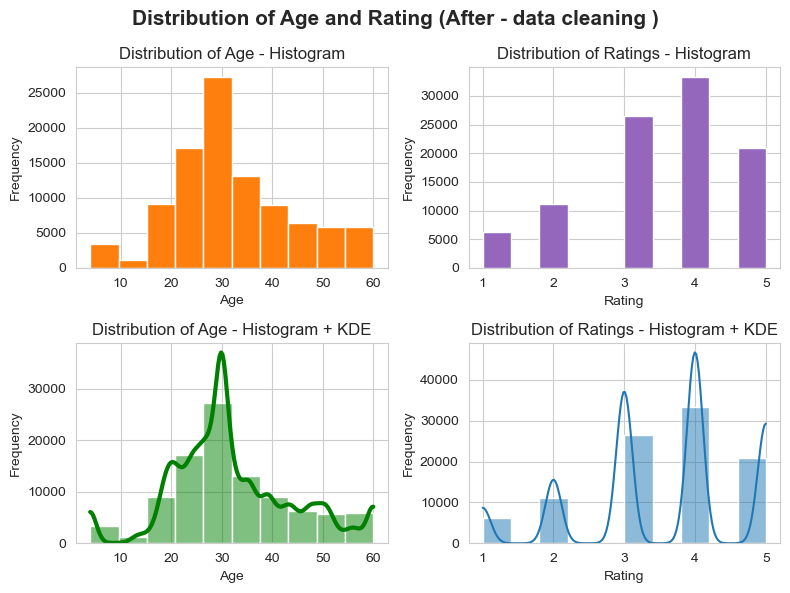

In [88]:
# Histogram & KDE
# Distribution of ratings and Age - histogram & KDE
fig, axes = plt.subplots(2, 2, figsize=(8, 6),)

axes[0, 0].hist(movies_ratings['age'], color='tab:orange')
axes[0, 1].hist(movies_ratings['rating'], color='tab:purple', histtype='stepfilled')
sns.histplot(movies_ratings['age'], kde=True, ax=axes[1, 0], bins=10, line_kws={'linewidth':3}, color='green')
sns.histplot(movies_ratings['rating'], kde=True, ax=axes[1, 1], bins=10)

# Customise plot
# Titles
fig.suptitle('Distribution of Age and Rating (After - data cleaning )', fontsize=15, fontweight='bold')
axes[0, 0].set_title('Distribution of Age - Histogram')
axes[0, 1].set_title('Distribution of Ratings - Histogram')
axes[1, 0].set_title('Distribution of Age - Histogram + KDE')
axes[1, 1].set_title('Distribution of Ratings - Histogram + KDE')

# Axis labels
axes[0, 0].set_xlabel('Age')
axes[0, 0].set_ylabel('Frequency')
axes[0, 1].set_xlabel('Rating')
axes[0, 1].set_ylabel('Frequency')
axes[1, 0].set_xlabel('Age')
axes[1, 0].set_ylabel('Frequency')
axes[1, 1].set_xlabel('Rating')
axes[1, 1].set_ylabel('Frequency')


fig.tight_layout()


plt.show();

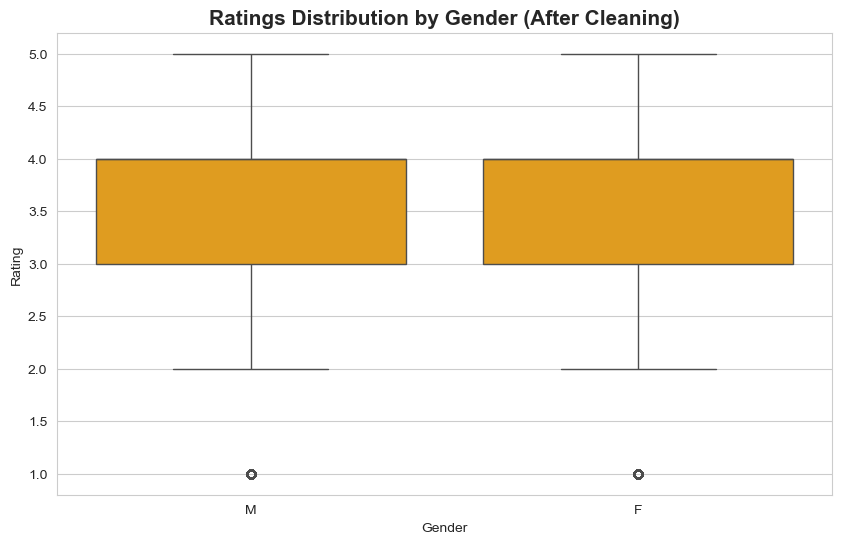

In [89]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=movies_ratings, x='gender', y='rating', color='orange')
plt.title('Ratings Distribution by Gender (After Cleaning)', fontsize=15, fontweight='bold')
plt.xlabel('Gender')
plt.ylabel('Rating')
plt.show()

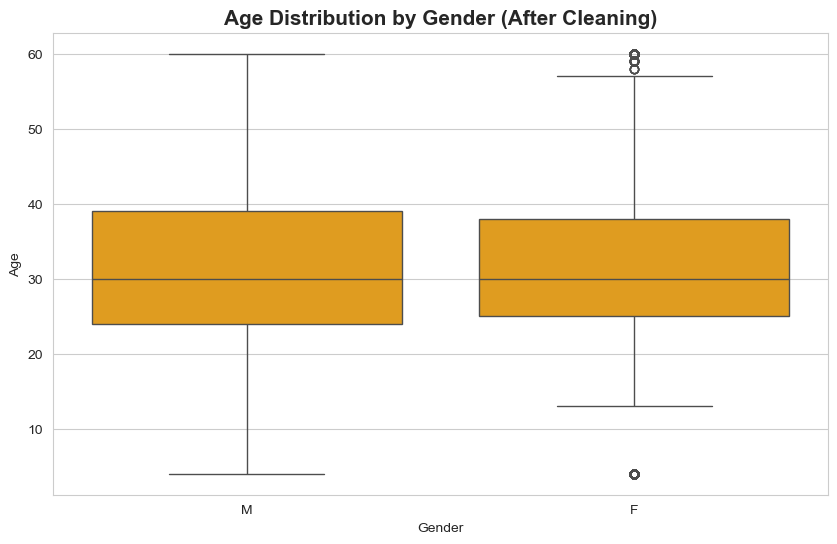

In [90]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=movies_ratings, x='gender', y='age', color='orange')
plt.title('Age Distribution by Gender (After Cleaning)', fontsize=15, fontweight='bold')
plt.xlabel('Gender')
plt.ylabel('Age')
plt.show()

> We have the same age median for both male and females 

> There is a rating from an unrealistic age - 4 years old female

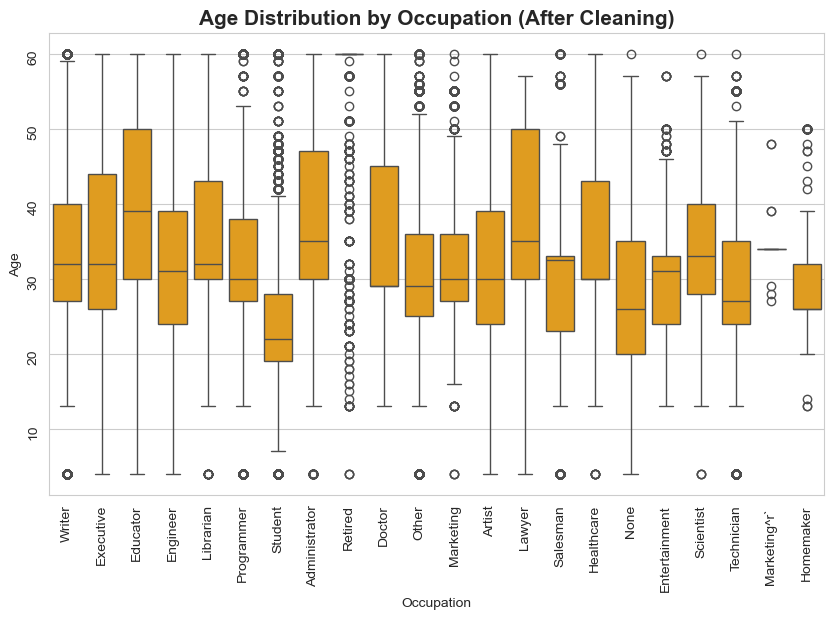

In [91]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=movies_ratings, x='occupation', y='age', color='orange')
plt.title('Age Distribution by Occupation (After Cleaning)', fontsize=15, fontweight='bold')
plt.xlabel('Occupation')
plt.ylabel('Age')

plt.tick_params(labelrotation=90)
plt.show()

**Median Age:** The median age (central line in each box) varies across occupations. For example, it appears highest for Lawyers and Doctors (around 50-60), while it is lower for Students (around 20-30) and Homemakers (around 30-40).

**Interquartile Range (IQR):** The height of each box represents the IQR (middle 50% of the data). Occupations like Lawyer, Doctor, and Executive show a wider IQR (greater age variability), while Student and Homemaker have narrower IQRs, indicating less variability.

**Whiskers:** The whiskers extend to the minimum and maximum ages within 1.5 times the IQR. Some occupations (e.g., Retired) have long whiskers, suggesting a broader age range, while others (e.g., Student) have shorter whiskers, indicating a more concentrated age group.

**Outliers:** Several occupations, such as Retired, Lawyer, and Doctor, have numerous outliers (dots beyond the whiskers), indicating individuals significantly older or younger than the typical range for those professions.

**General Trends:** Professions like Executive, Engineer, and Programmer have median ages around 40-50 with moderate variability. Healthcare and Salesman show similar medians but with more outliers. 

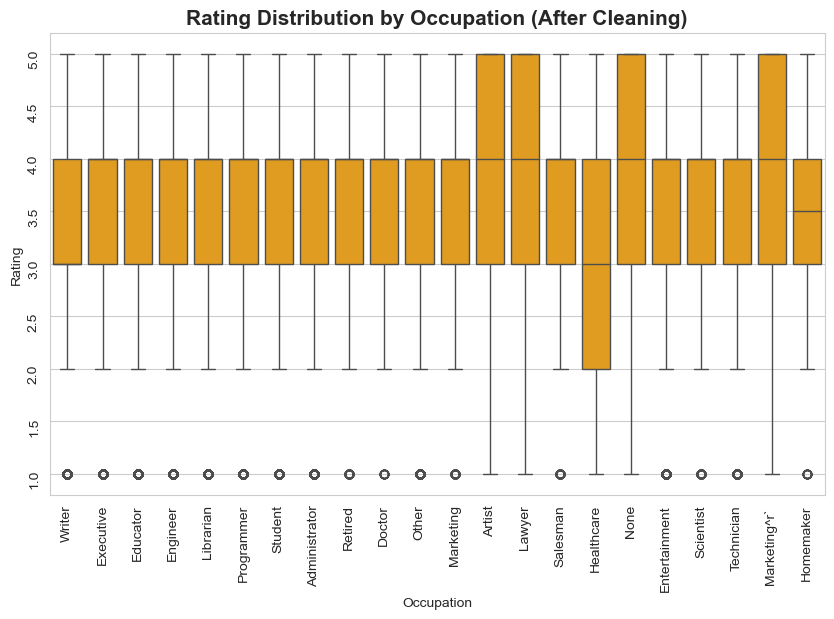

In [92]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=movies_ratings, x='occupation', y='rating', color='orange')
plt.title('Rating Distribution by Occupation (After Cleaning)', fontsize=15, fontweight='bold')
plt.xlabel('Occupation')
plt.ylabel('Rating')

plt.tick_params(labelrotation=90)
plt.show()

**General Trends:** Ratings are consistently high (3.5-4.5) for most occupations like Writer, Engineer, Doctor, and Artist, with Lawyers and Artists peaking highest. Salesmen have a significantly lower median and wider spread, suggesting more variability and generally lower ratings

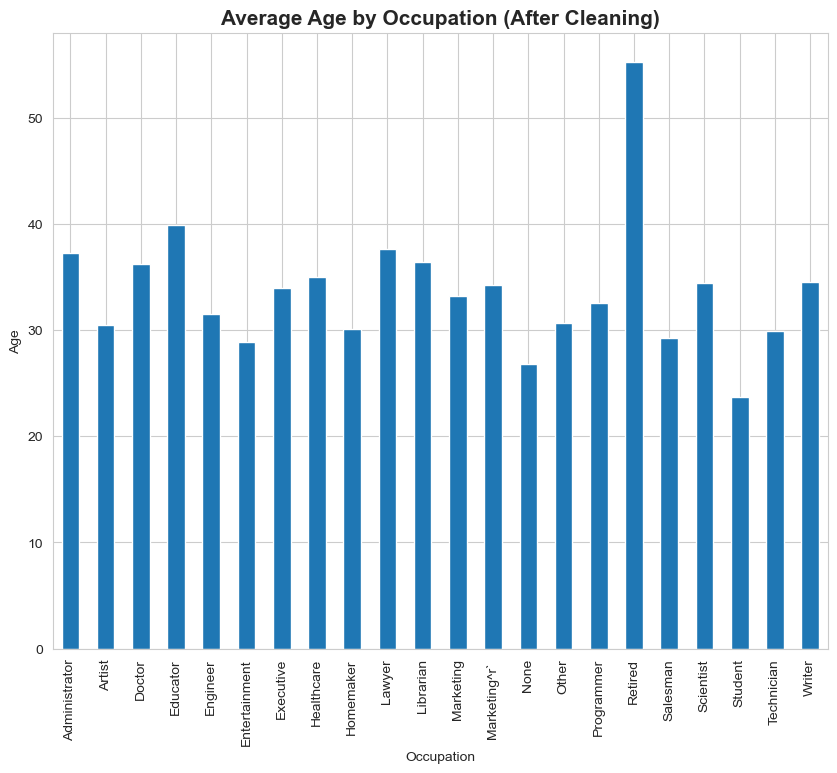

In [93]:
# Bar Charts
# Average Age per occupation
plt.figure(figsize=(10,8 ))
movies_ratings.groupby('occupation')['age'].mean().plot.bar()
plt.title('Average Age by Occupation (After Cleaning)', fontsize=15, fontweight='bold')
plt.xlabel('Occupation')
plt.ylabel('Age');

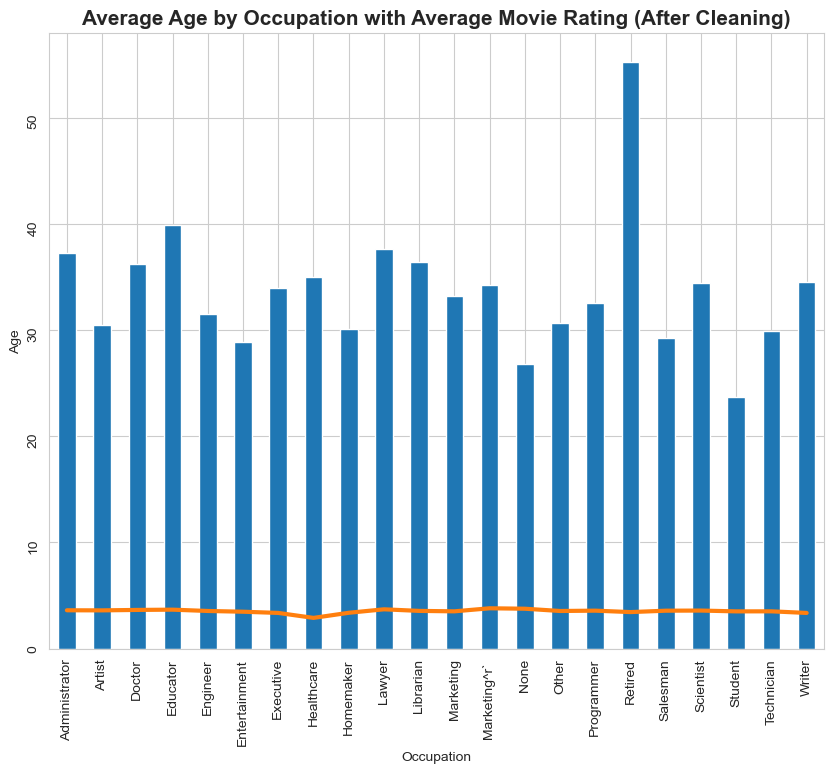

In [94]:
# Average Age per occupation with rating 
fig, ax = plt.subplots(figsize=(10,8 ))
movies_ratings.groupby('occupation')['age'].mean().plot.bar(ax=ax)
movies_ratings.groupby('occupation')['rating'].mean().plot(ax=ax, color='tab:orange', linewidth=3)
plt.title('Average Age by Occupation with Average Movie Rating (After Cleaning)', fontsize=15, fontweight='bold')
plt.xlabel('Occupation')
plt.tick_params(labelrotation=90)
plt.ylabel('Age');

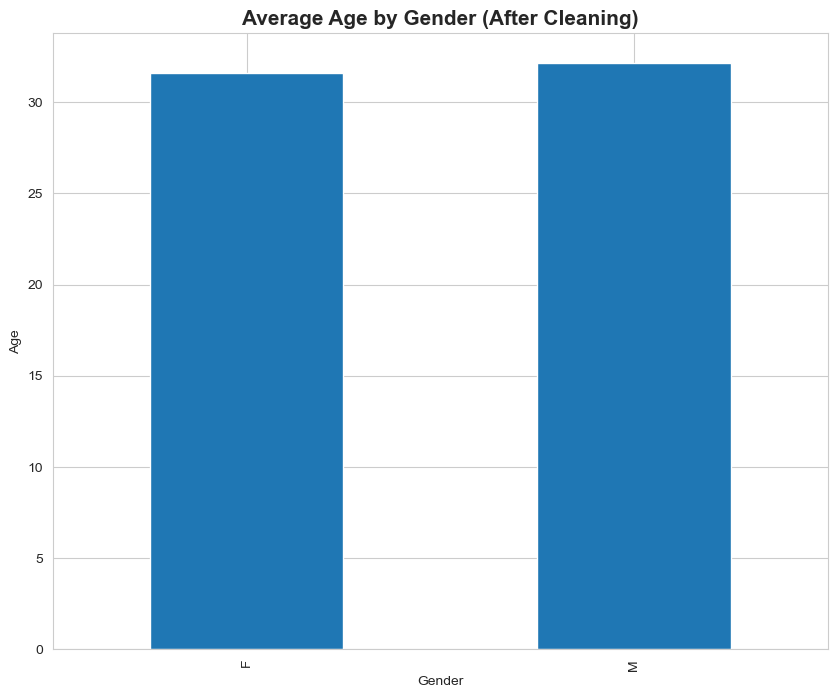

In [95]:
# Average Age per Gender
plt.figure(figsize=(10,8 ))
movies_ratings.groupby('gender')['age'].mean().plot(kind='bar')
plt.title('Average Age by Gender (After Cleaning)', fontsize=15, fontweight='bold')
plt.xlabel('Gender')
plt.ylabel('Age');

> The average is close between male and female with male slightly older

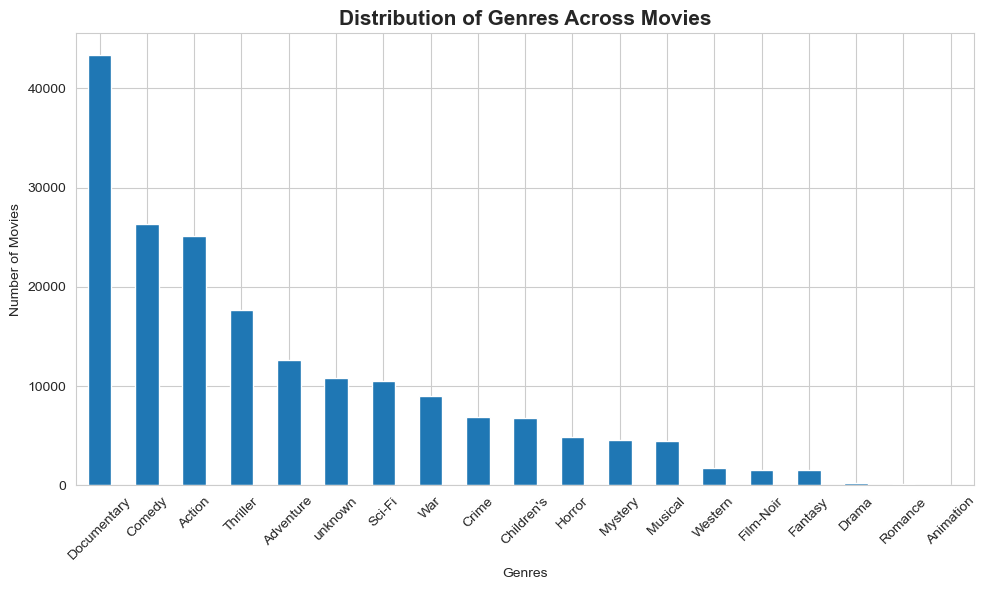

In [96]:
# Bar Plot of Genre Distribution

valid_genres = ['Action', 'Adventure', 'Animation', 'Children\'s', 'Comedy', 'Crime', 
                'Documentary', 'Drama', 'Fantasy', 'Film-Noir', 'Horror', 'Musical', 
                'Mystery', 'Romance', 'Sci-Fi', 'Thriller', 'War', 'Western', 'unknown']

genre_counts = movies_ratings[valid_genres].sum().sort_values(ascending=False)
plt.figure(figsize=(10, 6))
genre_counts.plot(kind='bar')

plt.title('Distribution of Genres Across Movies', fontsize=15, fontweight='bold')
plt.xlabel('Genres')
plt.ylabel('Number of Movies')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

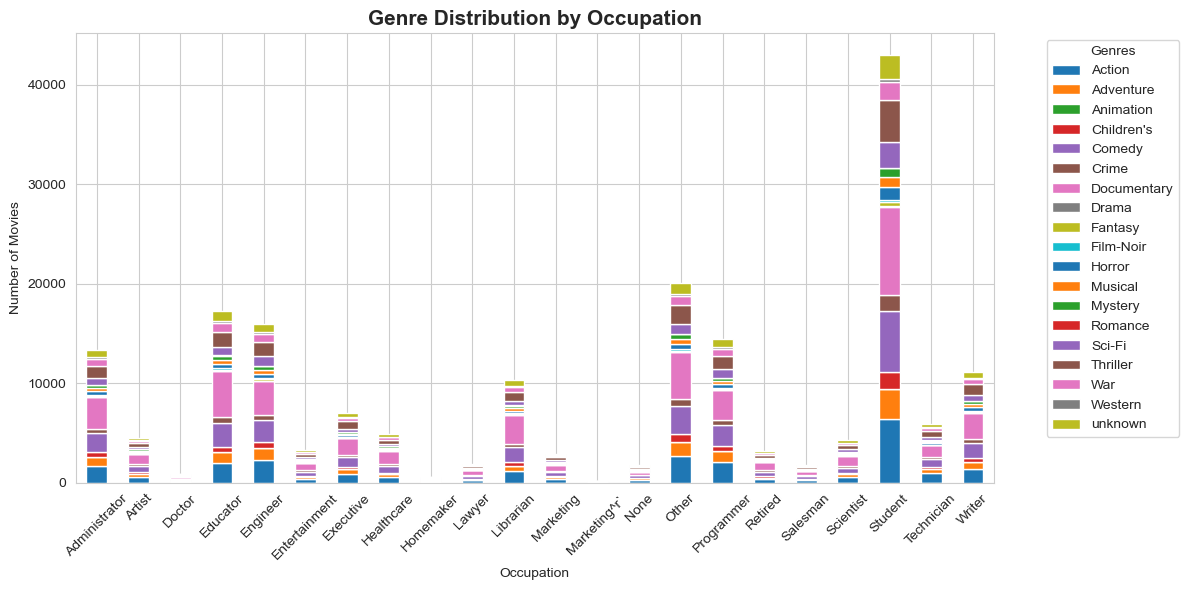

In [97]:
# Stacked Bar Plot of Genre by Occupation
occupation_genre = movies_ratings.groupby('occupation')[valid_genres].sum()

fig, ax = plt.subplots(figsize=(12, 6))

occupation_genre.plot(kind='bar', stacked=True, ax=ax)

plt.title('Genre Distribution by Occupation', fontsize=15, fontweight='bold')
plt.xlabel('Occupation')
plt.ylabel('Number of Movies')
plt.xticks(rotation=45)
plt.legend(title='Genres', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

**Insight-Driven Questions and Analysis**

In [98]:
# Question 1: What is the average movie rating grouped by genger ?
mean_ratings = movies_ratings.pivot_table('rating', index='movie title', columns='gender', aggfunc='mean', fill_value=0)

In [99]:
mean_ratings[:5]

gender,F,M
movie title,,
kldum klaka (Cold Fever) (1994),3.000000,0.000000
'Til There Was You (1997),2.166667,2.666667
1-900 (1994),1.000000,3.000000
101 Dalmatians (1996),3.108108,2.808824
12 Angry Men (1957),4.280000,4.278351


In [100]:
# Question 2: Which movies received the highest count of ratings - top 20
movies_ratings['movie title'].value_counts()[:20]

movie title
Star Wars (1977)                    579
Return of the Jedi (1983)           498
Contact (1997)                      496
Fargo (1996)                        495
Liar Liar (1997)                    477
English Patient, The (1996)         469
Scream (1996)                       466
Toy Story (1995)                    443
Air Force One (1997)                425
Raiders of the Lost Ark (1981)      414
Independence Day (ID4) (1996)       413
Godfather, The (1972)               403
Twelve Monkeys (1995)               388
Pulp Fiction (1994)                 386
Silence of the Lambs, The (1991)    384
Jerry Maguire (1996)                374
Chasing Amy (1997)                  371
Rock, The (1996)                    369
Empire Strikes Back, The (1980)     359
Star Trek: First Contact (1996)     356
Name: count, dtype: int64

In [101]:
# Question 3: Which movies received the lowest count of ratings - bottom  20
movies_ratings['movie title'].value_counts(ascending=True)[:20]

movie title
Dadetown (1995)                                              1
The Courtyard (1995)                                         1
Shopping (1994)                                              1
Yankee Zulu (1994)                                           1
Lady of Burlesque (1943)                                     1
Entertaining Angels: The Dorothy Day Story (1996)            1
Eye of Vichy, The (Oeil de Vichy, L') (1993)                 1
Favor, The (1994)                                            1
Bird of Prey (1996)                                          1
Raw Deal (1948)                                              1
Wend Kuuni (God's Gift) (1982)                               1
Liebelei (1933)                                              1
Leopard Son, The (1996)                                      1
Little City (1998)                                           1
Big One, The (1997)                                          1
Lashou shentan (1992)                      

In [102]:
# Question 4: What is the average rating of the top 20 movies by number of ratings received
top_twenty = movies_ratings['movie title'].value_counts()[:20]


In [103]:
mean_ratings.loc[top_twenty.index]

gender,F,M
movie title,,
Star Wars (1977),4.298013,4.373832
Return of the Jedi (1983),3.974576,4.002632
Contact (1997),3.746269,3.831492
Fargo (1996),4.024390,4.188172
Liar Liar (1997),3.045455,3.202899
"English Patient, The (1996)",3.908451,3.550459
Scream (1996),3.416667,3.461078
Toy Story (1995),3.798319,3.895062
Air Force One (1997),3.695652,3.580645


In [104]:
top_20 = mean_ratings.loc[top_twenty.index].sort_values('M', ascending=False)

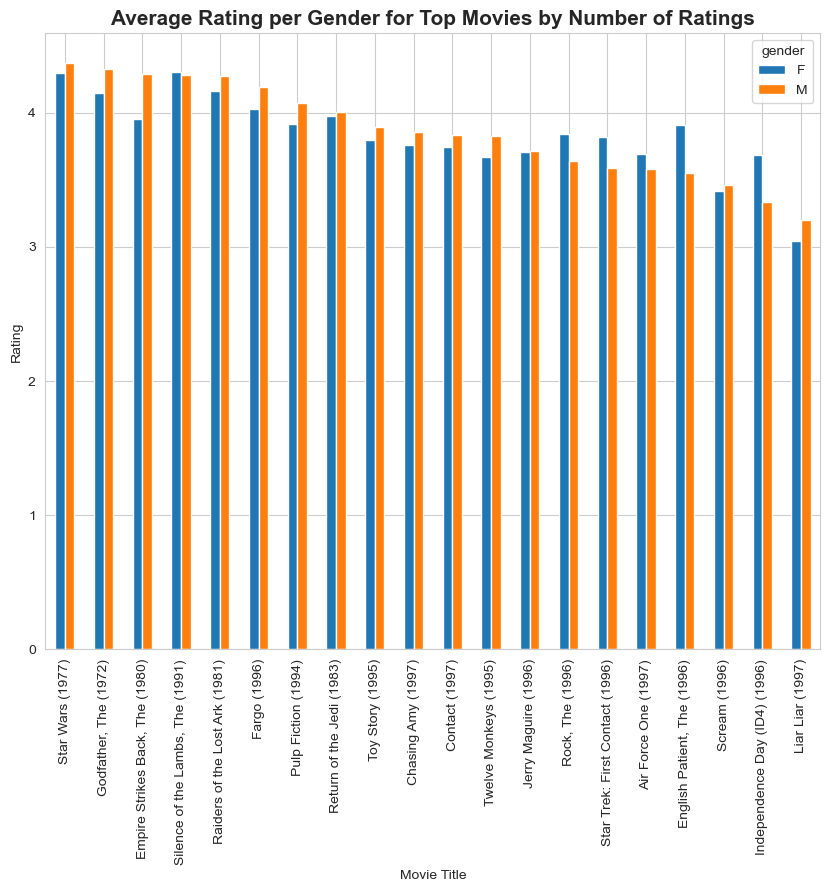

In [105]:
fig, ax = plt.subplots(figsize=(10, 8))
top_20.plot.bar(ax=ax)
plt.title('Average Rating per Gender for Top Movies by Number of Ratings', fontsize=15, fontweight='bold')
plt.xlabel('Movie Title')
plt.ylabel('Rating');

In [106]:
# Question 5: What is top movies among female viewers
top_female_ratings = mean_ratings.sort_values(by='F', ascending=False)

In [107]:
top_female_ratings[:10]

gender,F,M
movie title,,
Maya Lin: A Strong Clear Vision (1994),5.0,4.333333
Everest (1998),5.0,4.000000
Stripes (1981),5.0,3.500000
"Visitors, The (Visiteurs, Les) (1993)",5.0,2.000000
Foreign Correspondent (1940),5.0,3.785714
Chairman of the Board (1998),5.0,2.000000
Telling Lies in America (1997),5.0,3.083333
"Whole Wide World, The (1996)",5.0,3.750000
Prefontaine (1997),5.0,5.000000


In [108]:
# Question 6: What is top movies among male  viewers
top_male_ratings = mean_ratings.sort_values(by='M', ascending=False)

In [109]:
top_male_ratings[:10]

gender,F,M
movie title,,
Delta of Venus (1994),1.000000,5.0
"Saint of Fort Washington, The (1993)",0.000000,5.0
Love Serenade (1996),2.333333,5.0
Entertaining Angels: The Dorothy Day Story (1996),0.000000,5.0
Santa with Muscles (1996),0.000000,5.0
"Letter From Death Row, A (1998)",4.000000,5.0
"Quiet Room, The (1996)",3.000000,5.0
"Great Day in Harlem, A (1994)",0.000000,5.0
Marlene Dietrich: Shadow and Light (1996),0.000000,5.0


In [110]:
# Question 7:movies that are most divisive between male and female
# add a column to mean_ratings containing the difference in means,
mean_ratings['diff'] = mean_ratings['M'] - mean_ratings['F']

In [111]:
sorted_by_diff = mean_ratings.sort_values(by='diff')

# Movies preferred by women - rated high by female but low by male
sorted_by_diff[:10]

gender,F,M,diff
movie title,,,
Someone Else's America (1995),5.0,0.0,-5.0
Some Mother's Son (1996),4.5,0.0,-4.5
"Butcher Boy, The (1998)",4.0,0.0,-4.0
"Object of My Affection, The (1998)",4.0,0.0,-4.0
"Spanish Prisoner, The (1997)",4.0,0.0,-4.0
Brothers in Trouble (1995),4.0,0.0,-4.0
Nico Icon (1995),4.0,0.0,-4.0
"Silence of the Palace, The (Saimt el Qusur) (1994)",3.0,0.0,-3.0
Chairman of the Board (1998),5.0,2.0,-3.0


In [112]:
# Movies preferred by men - rated high by male but low by female
sorted_by_diff[::-1][:10]

gender,F,M,diff
movie title,,,
Marlene Dietrich: Shadow and Light (1996),0.0,5.000,5.000
Star Kid (1997),0.0,5.000,5.000
Santa with Muscles (1996),0.0,5.000,5.000
"Great Day in Harlem, A (1994)",0.0,5.000,5.000
Entertaining Angels: The Dorothy Day Story (1996),0.0,5.000,5.000
"Saint of Fort Washington, The (1993)",0.0,5.000,5.000
Pather Panchali (1955),0.0,4.625,4.625
Anna (1996),0.0,4.500,4.500
"Innocents, The (1961)",0.0,4.250,4.250


In [113]:
# Question 8: movies that elicited the most disagreement among viewers, independent of gender identification.


> Disagreement can be measured by the variance or standard deviation of the ratings:

In [114]:
rating_std_by_title = movies_ratings.groupby('movie title')['rating'].std()

In [115]:
rating_std_by_title.sort_values(ascending=False)[:20]

movie title
The Deadly Cure (1996)                                2.828427
Tough and Deadly (1995)                               2.828427
Delta of Venus (1994)                                 2.828427
Hugo Pool (1997)                                      2.138090
New York Cop (1996)                                   2.121320
Wooden Man's Bride, The (Wu Kui) (1994)               2.121320
Spirits of the Dead (Tre passi nel delirio) (1968)    2.121320
Visitors, The (Visiteurs, Les) (1993)                 2.121320
American Dream (1990)                                 2.121320
Open Season (1996)                                    2.121320
Love and Death on Long Island (1997)                  2.121320
Rough Magic (1995)                                    2.121320
Convent, The (Convento, O) (1995)                     2.121320
Total Eclipse (1995)                                  2.081666
For the Moment (1994)                                 2.081666
Boys, Les (1997)                           

**Example Problem Statements**

1. **Predictive Modeling:** Can we predict the rating a user will give to a movie based on their age, gender, occupation, and the movie's genre?
2.**Recommendation System:** How can we develop a personalized movie recommendation system that suggests movies to users based on their historical ratings and demographic information?
3. **Genre Preference Analysis:** What are the most popular genres among different age groups, and how do these preferences vary by occupation?
4. **Temporal Trends:** How have movie ratings and genre popularity evolved over time based on the release dates of the movies?
5. **User Segmentation:** Can we segment users into distinct groups based on their rating patterns and demographic features to improve targeted marketing strategies?
6. **Bias Detection:** Is there a bias in ratings based on gender or occupation, and how does it affect the overall dataset?
7. **Genre Combination Impact:** Do certain combinations of genres (e.g., Action and Sci-Fi) lead to higher average ratings compared to single-genre movies?